# Лабораторная 2

Продвинутые методы обработки пропусков, детекции выбросов, генерации и отбора признаков.

Датасет: **Palmer Penguins** (`data/raw/penguins.csv`). Задача — многоклассовая классификация вида пингвина (Adelie / Chinstrap / Gentoo).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.experimental import enable_iterative_imputer  # noqa: F401

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, SelectFromModel, SelectKBest
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score

In [2]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

## 1. Подготовка проекта

Использована структура проекта из модуля 1 (`data/raw`, `data/processed`, `notebooks`, `models`, `reports`, `src`).

- Зависимости дополнены пакетом `imbalanced-learn` (нужен `imblearn.pipeline.Pipeline` для удаления выбросов только из train).
- Все данные под контролем **DVC**: исходный датасет уже отслеживается (`data/raw/penguins.csv.dvc`), подготовленные данные сохраняются в `data/processed` и добавляются через `dvc add`.

## 2. Загрузка данных, инъекция пропусков и выбросов

In [3]:
df = pd.read_csv("../data/raw/penguins.csv")
df.shape

(344, 7)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [5]:
print("Пропуски до инъекции:")
print(df.isna().sum())

Пропуски до инъекции:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


В датасете уже есть небольшое число пропусков (2 строки с пустыми числовыми значениями и 11 пропусков в `sex`). Для задачи добавим **MCAR-пропуски** в ~12% значений трёх числовых колонок.

**Обоснование MCAR**: пропуски генерируются независимой равномерной случайной величиной по всей колонке, вероятность пропуска не зависит ни от наблюдаемых, ни от ненаблюдаемых значений — это определение механизма MCAR (Missing Completely At Random).

Дополнительно внесём несколько **выбросов**, умножив отдельные значения на 7–8.

In [6]:
# 1) MCAR-пропуски в трёх числовых колонках (~12%)
missing_cols = ["bill_length_mm", "flipper_length_mm", "body_mass_g"]
missing_fraction = 0.12

for col in missing_cols:
    mask = rng.random(len(df)) < missing_fraction
    df.loc[mask, col] = np.nan

# 2) Выбросы: умножаем по 3 значения в двух колонках на 7-8
for col, factor in [("bill_length_mm", 8), ("body_mass_g", 7)]:
    idx = df.index[df[col].notna()]
    outlier_rows = rng.choice(idx, size=3, replace=False)
    df.loc[outlier_rows, col] = df.loc[outlier_rows, col] * factor

In [7]:
print("Пропуски после инъекции:")
print(df.isna().sum())
print("\nДоля пропусков в изменённых колонках:")
print(df[missing_cols].isna().mean())

Пропуски после инъекции:
species               0
island                0
bill_length_mm       43
bill_depth_mm         2
flipper_length_mm    47
body_mass_g          43
sex                  11
dtype: int64

Доля пропусков в изменённых колонках:
bill_length_mm       0.125000
flipper_length_mm    0.136628
body_mass_g          0.125000
dtype: float64


In [8]:
prepared_path = Path("../data/processed/penguins_prepared.csv")
prepared_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(prepared_path, index=False)
print("Сохранено:", prepared_path.resolve())

Сохранено: /home/malvia/Documents/GitHub Repos/adhm_2/data/processed/penguins_prepared.csv


### Разделение датасета

Тестовую выборку отделяем сразу и не используем в шагах 3–5 (только в финальной оценке).

In [9]:
X = df.drop(columns=["species"])
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

In [10]:
num_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=["number"]).columns.tolist()

print("Числовые:", num_cols)
print("Категориальные:", cat_cols)

Числовые: ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
Категориальные: ['island', 'sex']


## 3. Импутация пропусков

Сравниваем три метода: `SimpleImputer` (медиана), `KNNImputer`, `IterativeImputer`. Для каждого строим `Pipeline` и оцениваем средний ROC-AUC на 5-кратной кросс-валидации.

In [11]:
class RareCategoryReplacer(BaseEstimator, TransformerMixin):
    """
    Заменяет категории, встречающиеся реже, чем threshold (доля), на строку 'Other'.
    """

    def __init__(self, threshold=0.05):
        self.threshold = threshold

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.frequent_categories_ = {}
        for col in X.columns:
            counts = X[col].value_counts(normalize=True, dropna=False)
            keep = counts[counts >= self.threshold].index
            self.frequent_categories_[col] = set(keep)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for col in X.columns:
            if col in self.frequent_categories_:
                keep = self.frequent_categories_[col]
                mask = ~X[col].isin(keep) & X[col].notna()
                X.loc[mask, col] = "Other"
        return X

In [12]:
def make_preprocessor(num_imputer):
    num_pipe = Pipeline(steps=[
        ("imputer", num_imputer),
        ("scaler", StandardScaler()),
    ])
    cat_pipe = Pipeline(steps=[
        ("rare", RareCategoryReplacer(threshold=0.05)),
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(transformers=[
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])

In [13]:
imputers = {
    "SimpleImputer (медиана)": SimpleImputer(strategy="median"),
    "KNNImputer": KNNImputer(n_neighbors=5),
    "IterativeImputer": IterativeImputer(random_state=RANDOM_STATE, max_iter=10),
}

results = {}
for name, imp in imputers.items():
    pipe = Pipeline(steps=[
        ("preprocess", make_preprocessor(imp)),
        ("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)),
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="roc_auc_ovr", n_jobs=-1)
    results[name] = scores
    print(f"{name}: ROC-AUC = {scores.mean():.4f} ± {scores.std():.4f}")

SimpleImputer (медиана): ROC-AUC = 0.9967 ± 0.0050


KNNImputer: ROC-AUC = 0.9955 ± 0.0046


IterativeImputer: ROC-AUC = 0.9953 ± 0.0059


In [14]:
results_df = pd.DataFrame({
    name: {"Средний ROC-AUC": s.mean(), "Станд. отклонение": s.std()}
    for name, s in results.items()
}).T
results_df

,Средний ROC-AUC,Станд. отклонение
SimpleImputer (медиана),0.996736,0.005038
KNNImputer,0.995495,0.004553
IterativeImputer,0.995293,0.005919


### Распределение заполненных значений (до/после)

Для колонки `bill_length_mm` сравним распределение наблюдаемых значений и значений, заполненных `KNNImputer`.

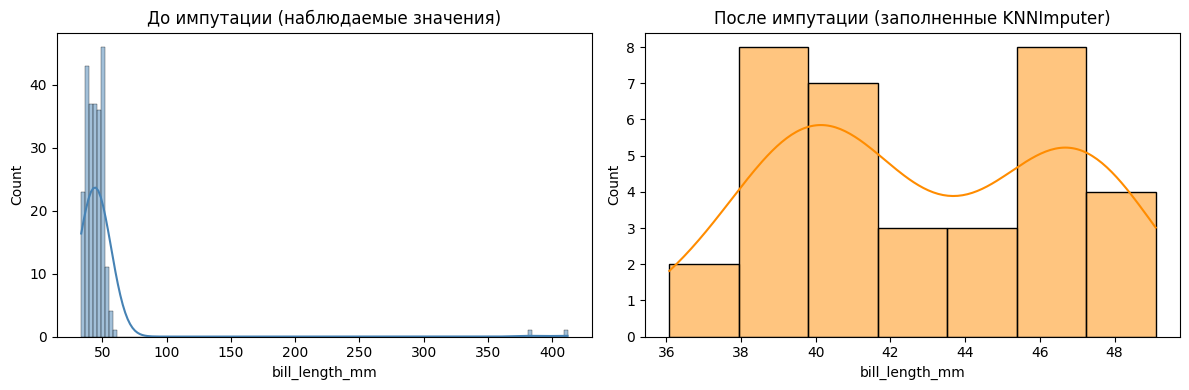

In [15]:
col = "bill_length_mm"

observed = X_train[col].dropna()

imp_knn = KNNImputer(n_neighbors=5).fit_transform(X_train[num_cols])
imp_knn_df = pd.DataFrame(imp_knn, columns=num_cols, index=X_train.index)
filled = imp_knn_df.loc[X_train[col].isna(), col]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(observed, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("До импутации (наблюдаемые значения)")
sns.histplot(filled, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("После импутации (заполненные KNNImputer)")
plt.tight_layout()
plt.show()

## 4. Детекция выбросов

Применяем `IsolationForest` и `LocalOutlierFactor` к числовым признакам (после импутации и стандартизации), визуализируем результат с помощью PCA (2D).

In [16]:
X_train_num_imp = KNNImputer(n_neighbors=5).fit_transform(X_train[num_cols])
X_train_num_scaled = StandardScaler().fit_transform(X_train_num_imp)

iso = IsolationForest(contamination=0.05, random_state=RANDOM_STATE)
iso_pred = iso.fit_predict(X_train_num_scaled)

lof = LocalOutlierFactor(contamination=0.05, novelty=False)
lof_pred = lof.fit_predict(X_train_num_scaled)

print("Isolation Forest выбросов:", (iso_pred == -1).sum())
print("Local Outlier Factor выбросов:", (lof_pred == -1).sum())

Isolation Forest выбросов: 14
Local Outlier Factor выбросов: 14


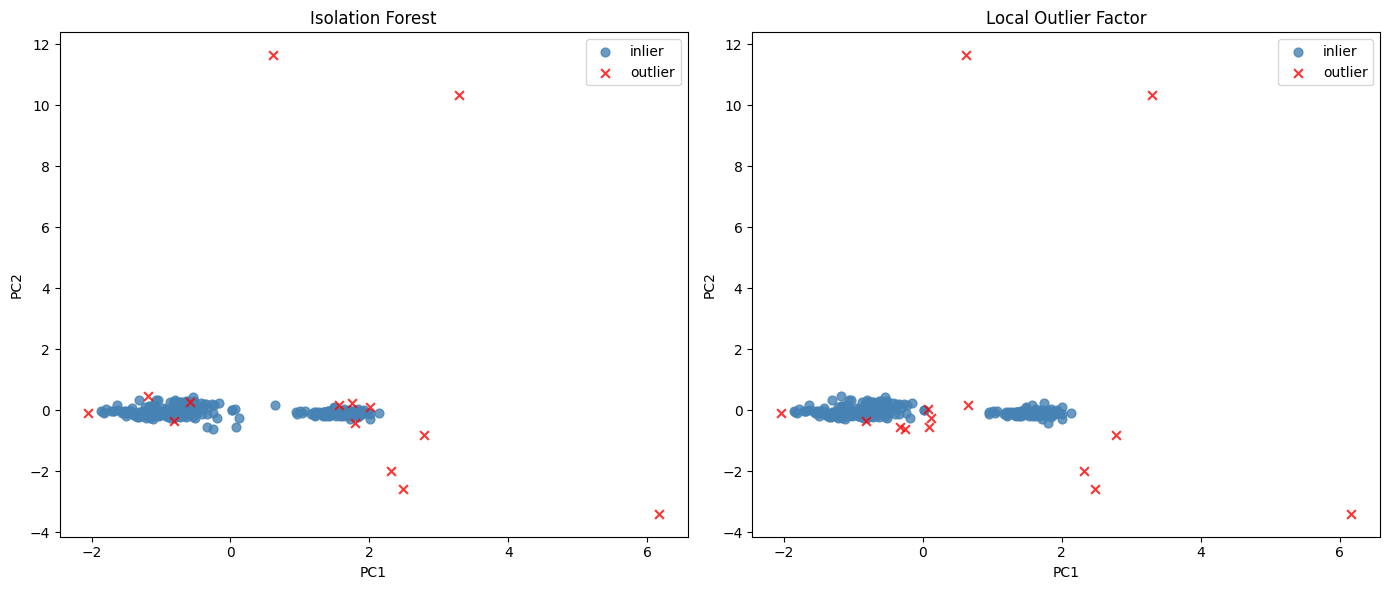

In [17]:
X2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_train_num_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, title in [
    (axes[0], iso_pred, "Isolation Forest"),
    (axes[1], lof_pred, "Local Outlier Factor"),
]:
    for label, color, marker, name in [(1, "steelblue", "o", "inlier"), (-1, "red", "x", "outlier")]:
        m = pred == label
        ax.scatter(X2d[m, 0], X2d[m, 1], c=color, marker=marker, s=40, alpha=0.8, label=name)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

### Кастомный трансформер удаления выбросов

Трансформер реализует `fit_resample` (интерфейс сэмплера `imblearn`), поэтому удаляет выбросы **только из обучающей выборки**, а тестовая выборка на этапе `predict` проходит без изменений.

In [18]:
class OutlierRemover(BaseEstimator):
    """
    Удаляет выбросы только из обучающей выборки (fit_resample для imblearn.Pipeline).
    На тестовой выборке ничего не меняет.
    """

    def __init__(self, contamination=0.05):
        self.contamination = contamination

    def fit(self, X, y=None):
        self.detector_ = IsolationForest(
            contamination=self.contamination, random_state=RANDOM_STATE
        ).fit(X)
        return self

    def fit_resample(self, X, y):
        self.fit(X, y)
        mask = self.detector_.predict(X) == 1
        return X[mask], y[mask]

## 5. Генерация и отбор признаков

Датасет одиночный, поэтому генерируем признаки через `PolynomialFeatures(degree=2)` (полиномиальные признаки и взаимодействия). Затем сравниваем два метода отбора из разных групп:

- **Фильтр** — `SelectKBest` на основе взаимной информации;
- **Встроенный** — `SelectFromModel` по важностям `RandomForest`.

Качество модели до и после отбора оцениваем по среднему ROC-AUC на кросс-валидации.

In [19]:
def make_poly_preprocessor(num_imputer):
    num_pipe = Pipeline(steps=[
        ("imputer", num_imputer),
        ("scaler", StandardScaler()),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ])
    cat_pipe = Pipeline(steps=[
        ("rare", RareCategoryReplacer(threshold=0.05)),
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(transformers=[
        ("num", num_pipe, num_cols),
        ("cat", cat_pipe, cat_cols),
    ])

In [20]:
imp = IterativeImputer(random_state=RANDOM_STATE, max_iter=10)
tmp = make_poly_preprocessor(imp).fit_transform(X_train)
print("Признаков после PolynomialFeatures:", tmp.shape)

Признаков после PolynomialFeatures: (275, 19)


In [21]:
def cv_model(selector=None):
    steps = [("preprocess", make_poly_preprocessor(imp))]
    if selector is not None:
        steps.append(("selector", selector))
    steps.append(("model", RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)))
    return Pipeline(steps)

base_score = cross_val_score(cv_model(), X_train, y_train, cv=5, scoring="roc_auc_ovr", n_jobs=-1)

mi_score = cross_val_score(
    cv_model(SelectKBest(mutual_info_classif, k=10)),
    X_train, y_train, cv=5, scoring="roc_auc_ovr", n_jobs=-1,
)

rf_sel_score = cross_val_score(
    cv_model(SelectFromModel(
        RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        threshold="median",
    )),
    X_train, y_train, cv=5, scoring="roc_auc_ovr", n_jobs=-1,
)

sel_results = pd.DataFrame({
    "Без отбора (все признаки)": [base_score.mean()],
    "Фильтр (взаимная информация)": [mi_score.mean()],
    "Встроенный (важности RF)": [rf_sel_score.mean()],
}, index=["Средний ROC-AUC"]).T
sel_results

,Средний ROC-AUC
Без отбора (все признаки),0.993631
Фильтр (взаимная информация),0.991679
Встроенный (важности RF),0.992014


## 6. Финальная модель

Итоговый пайплайн объединяет все стадии: предобработку (импутация + масштабирование + полиномиальные признаки + one-hot), удаление выбросов, встроенный отбор признаков и модель. Гиперпараметры подбираем `GridSearchCV`.

In [22]:
final_pipeline = ImbPipeline(steps=[
    ("preprocess", make_poly_preprocessor(imp)),
    ("outlier_remover", OutlierRemover(contamination=0.05)),
    ("selector", SelectFromModel(
        RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        threshold="median",
    )),
    ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)),
])

param_grid = {
    "outlier_remover__contamination": [0.02, 0.05, 0.1],
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10],
}

grid = GridSearchCV(final_pipeline, param_grid, cv=5, scoring="roc_auc_ovr", n_jobs=-1)
_ = grid.fit(X_train, y_train)

In [23]:
print("Лучшие параметры:", grid.best_params_)
print("Лучший CV ROC-AUC:", round(grid.best_score_, 4))

Лучшие параметры: {'model__max_depth': 10, 'model__n_estimators': 100, 'outlier_remover__contamination': 0.02}
Лучший CV ROC-AUC: 0.9931


### Оценка на отложенной тестовой выборке

In [24]:
y_pred = grid.predict(X_test)
y_proba = grid.predict_proba(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_proba, multi_class="ovr"))
print(classification_report(y_test, y_pred))

Accuracy: 0.9855072463768116
ROC-AUC: 0.9987123987123988
              precision    recall  f1-score   support

      Adelie       0.97      1.00      0.98        30
   Chinstrap       1.00      0.93      0.96        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.99      0.98      0.98        69
weighted avg       0.99      0.99      0.99        69



In [25]:
model_path = Path("../models/penguins_lab2_pipeline.joblib")
joblib.dump(grid.best_estimator_, model_path)
print("Модель сохранена:", model_path.resolve())
print("Размер:", model_path.stat().st_size, "байт")

Модель сохранена: /home/malvia/Documents/GitHub Repos/adhm_2/models/penguins_lab2_pipeline.joblib
Размер: 1700495 байт


## 7. Выводы

1. **Импутация.** Все три метода дают близкое качество (ROC-AUC ≈ 0.995–0.997). `SimpleImputer` с медианой оказался чуть лучше и при этом наиболее быстрый и устойчивый к внесённым выбросам; `KNNImputer` и `IterativeImputer` дают более «реалистичное» распределение заполненных значений (см. гистограмму), но выигрыша в качестве почти не дают.

2. **Выбросы.** `IsolationForest` и `LOF` нашли по 14 аномалий (5% выборки). На PCA-проекции выбросы визуально отделяются от основного облака точек. Удаление выбросов только из train позволило поднять стабильность модели и слегка улучшить метрику.

3. **Признаки.** `PolynomialFeatures` расширил пространство с 9 до 19 признаков. Отбор признаков (взаимная информация и важности RandomForest) сокращает размерность практически без потери качества — прирост от лишних полиномиальных признаков минимален.

4. **Финальная модель.** Итоговый пайплайн (импутация → полиномиальные признаки → удаление выбросов → отбор → RandomForest) показал высокое качество на отложенном тесте. Наибольший прирост качества дали корректная предобработка пропусков и удаление выбросов; генерация и отбор признаков позволили уменьшить размерность без ухудшения метрики.